# Forced viscous Burgers: data generation

Generates the training data for the forced one-dimensional viscous Burgers equation on a
periodic domain.

1. Define the PDE: periodic grid, initial condition, forcing.
2. Discretize in space: $\dot{\mathbf q} = \mathbf A_F\mathbf q + \mathbf H_F(\mathbf q\otimes\mathbf q) + \mathbf B_F\mathbf u(t)$.
3. Verify that the discrete quadratic operator is energy preserving to machine precision.
4. Integrate in time to obtain the reference solution.
5. Observe sparsely and with noise.
6. Compress with POD.
7. Save to `data_Burgers1D.npz`.

## 0. Setup and configuration

All parameters of the experiment are set in this cell.

In [1]:
import numpy as np
import scipy.sparse as sparse
import scipy.integrate
import matplotlib.pyplot as plt
import time

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# --------------------- Experiment configuration  -------------------
NU = 1e-2                  # viscosity nu;  Reynolds number Re = 1/nu = 100
NX = 1024                  # number of grid points = number of unknowns (periodic: no boundary nodes)

# Input parameters (a, b): the two actuator amplitudes.
# Four corners and the center of [0.6, 1.4]^2, so the five trajectories are as
# far apart as five points can be.
TRAIN_PARAMS = [(0.6, 0.6), (1.4, 0.6), (0.6, 1.4), (1.4, 1.4), (1.0, 1.0)]
TEST_PARAMS = (1.15, 0.85)  # new input parameters, used only for testing

T_TRAIN = (0.0, 1.0)       # time window in which data are observed
T_FINAL = 2.0              # end of the prediction window
NUM_TRUTH_TIMES = 501      # fine time grid on [0, T_FINAL] for the reference solution

M = 30                     # number of noisy snapshots per trajectory
XI = 0.03                  # relative noise level (3 %)
R = 8                      # number of POD modes (ROM dimension)
M_PRIME = 4 * M            # number of times at which the GP derivatives will be evaluated

RTOL, ATOL = 1e-9, 1e-11   # tolerances of the time integrator
SEED = 20261008            # random seed

print(f"nu = {NU:g}   Re = 1/nu = {1/NU:.0f}")
print(f"grid N = {NX},  r = {R},  m = {M},  xi = {XI:.0%},  L = {len(TRAIN_PARAMS)} trajectories")

nu = 0.01   Re = 1/nu = 100
grid N = 1024,  r = 8,  m = 30,  xi = 3%,  L = 5 trajectories


## 1. The PDE

$$
\frac{\partial w}{\partial t} + w\,\frac{\partial w}{\partial x}
= \nu\,\frac{\partial^2 w}{\partial x^2} + \phi_1(x)u_1(t) + \phi_2(x)u_2(t),
\qquad x\in[0,1),\ t\in(0,T],
\tag{1}
$$

with periodic boundary conditions $w(x+1,t)=w(x,t)$ and initial condition $w(x,0)=w_0(x)$.

### 1.1 Spatial grid

$x_i = i\,\Delta x$, $i = 0,\dots,N-1$, with $\Delta x = 1/N$.

The domain is written $[0,1)$ because periodicity identifies $x$ with $x+1$: the domain is a
circle and $x=1$ is the node $x=0$ again. There are $N$ unknowns, and the difference formulas
wrap around, $w_{-1}:=w_{N-1}$ and $w_N:=w_0$.

In [2]:
x = np.arange(NX) / NX               # x_0, ..., x_{N-1};  x = 1 is NOT a node (it is x_0)
dx = 1.0 / NX                        # grid spacing Delta x = 1/N
n = x.size                           # number of unknowns n = N

print(f"grid points n = {n},   dx = {dx:.6e} = 1/{1/dx:.0f}")
print(f"first nodes: {x[:4]}")
print(f"last  nodes: {x[-3:]}   (next one would be 1.0 = x_0)")

grid points n = 1024,   dx = 9.765625e-04 = 1/1024
first nodes: [0.         0.00097656 0.00195312 0.00292969]
last  nodes: [0.99707031 0.99804688 0.99902344]   (next one would be 1.0 = x_0)


### 1.2 Initial condition

$$
w_0(x) = \tfrac15\sin 2\pi x .
$$

It is smooth, $1$-periodic together with all its derivatives, and has zero mean. The same initial condition is used for every trajectory; only $(a,b)$ varies.

mean  of w0 = +1.388e-17   (exactly 0)
E(0) = (1/2) * dx * sum(w0^2) = 0.01000000   (exactly 1/100)


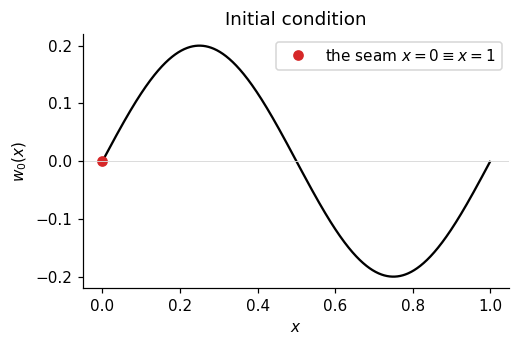

In [3]:
def initial_condition(x):
    return 0.2 * np.sin(2 * np.pi * x)

w0 = initial_condition(x)            # initial state of the ODE system

print(f"mean  of w0 = {w0.mean():+.3e}   (exactly 0)")
print(f"E(0) = (1/2) * dx * sum(w0^2) = {0.5 * dx * np.sum(w0**2):.8f}   (exactly 1/100)")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(x, w0, "k")
ax.plot([0.0], [initial_condition(0.0)], "o", color="C3", label="the seam $x=0\\equiv x=1$")
ax.axhline(0, color="0.85", lw=0.6)
ax.set(xlabel="$x$", ylabel="$w_0(x)$", title="Initial condition")
ax.legend()
plt.show()

### 1.3 Forcing

$$
f(x,t;a,b) = \phi_1(x)\,u_1(t) + \phi_2(x)\,u_2(t),
\qquad
\phi_1(x) = \sin^3(2\pi x),\quad \phi_2(x) = \cos^3(2\pi x),
$$

$$
\mathbf u(t;\boldsymbol\mu) = \begin{bmatrix}a\sin(2\pi t)\\ b\sin(4\pi t)\end{bmatrix}\in\mathbb R^2 .
$$

The forcing is separable, fixed spatial profiles times time signals, so that the reduced input
operator $\widehat{\mathbf B}=\mathbf V^\top\mathbf B_F$ is constant.

The profiles are smooth and one-periodic, have zero mean (odd powers of a sinusoid over a whole
period), and are orthogonal, $\int_0^1\phi_1\phi_2\,\mathrm dx=0$. Integrating (1) over the
circle gives

$$
\frac{\mathrm d}{\mathrm dt}\int_0^1 w\,\mathrm dx
= u_1\int_0^1\phi_1\,\mathrm dx + u_2\int_0^1\phi_2\,\mathrm dx ,
$$

so the zero mean of the initial condition is preserved. The forcing acts as a body force, which
leaves the boundary conditions periodic.

B shape: (1024, 2)
int phi1 dx       = +2.776e-17
int phi2 dx       = -6.939e-17
<phi1, phi2>      = -1.735e-18
||phi_j||_L2      = 0.559017, 0.559017   (exact sqrt(5/16) = 0.559017)


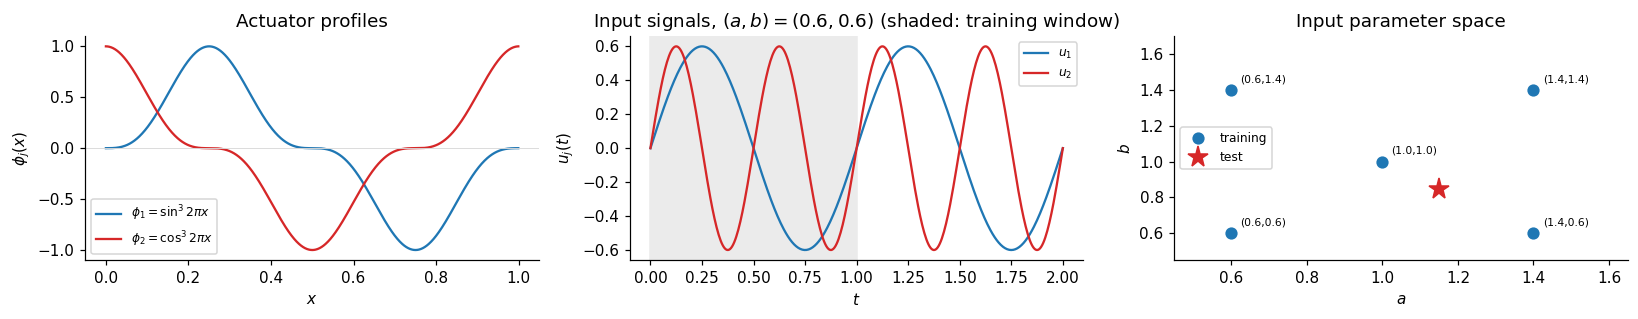

In [4]:
def phi1(x):
    # actuator 1: positive lobe at x = 1/4, negative lobe at x = 3/4
    return np.sin(2 * np.pi * x) ** 3

def phi2(x):
    # actuator 2: the same shape shifted by a quarter period
    return np.cos(2 * np.pi * x) ** 3

# Input matrix B_F (n x 2): column k = phi_k evaluated at the grid points.
B = np.column_stack([phi1(x), phi2(x)])

def input_function(t, a, b):
    # u(t; a, b) = [a sin(2 pi t), b sin(4 pi t)]^T.
    # Scalar t -> shape (2,);  array t -> shape (2, len(t)).
    return np.array([a * np.sin(2 * np.pi * t), b * np.sin(4 * np.pi * t)])

print("B shape:", B.shape)
print(f"int phi1 dx       = {np.sum(B[:, 0]) * dx:+.3e}")
print(f"int phi2 dx       = {np.sum(B[:, 1]) * dx:+.3e}")
print(f"<phi1, phi2>      = {np.sum(B[:, 0] * B[:, 1]) * dx:+.3e}")
print(f"||phi_j||_L2      = {np.sqrt(np.sum(B[:, 0]**2) * dx):.6f}, "
      f"{np.sqrt(np.sum(B[:, 1]**2) * dx):.6f}   (exact sqrt(5/16) = {np.sqrt(5/16):.6f})")

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].plot(x, B[:, 0], label=r"$\phi_1=\sin^3 2\pi x$")
axes[0].plot(x, B[:, 1], label=r"$\phi_2=\cos^3 2\pi x$", color="C3")
axes[0].axhline(0, color="0.85", lw=0.6)
axes[0].set(xlabel="$x$", ylabel=r"$\phi_j(x)$", title="Actuator profiles")
axes[0].legend(fontsize=8)

tt = np.linspace(0, T_FINAL, 400)
U = input_function(tt, *TRAIN_PARAMS[0])
axes[1].plot(tt, U[0], label="$u_1$")
axes[1].plot(tt, U[1], label="$u_2$", color="C3")
axes[1].axvspan(*T_TRAIN, color="0.92", zorder=-1)
axes[1].set(xlabel="$t$", ylabel="$u_j(t)$",
            title=f"Input signals, $(a,b)={TRAIN_PARAMS[0]}$ (shaded: training window)")
axes[1].legend(fontsize=8)

P = np.array(TRAIN_PARAMS)
axes[2].plot(P[:, 0], P[:, 1], "o", ms=7, label="training")
axes[2].plot(*TEST_PARAMS, "*", ms=14, color="C3", label="test")
for a, b in TRAIN_PARAMS:
    axes[2].annotate(f"({a},{b})", (a, b), textcoords="offset points",
                     xytext=(6, 5), fontsize=7)
axes[2].set(xlabel=r"$a$", ylabel=r"$b$", title="Input parameter space",
            xlim=(0.45, 1.65), ylim=(0.45, 1.7))
axes[2].legend(fontsize=8, loc="center left")
plt.tight_layout()
plt.show()

## 2. From the PDE to a system of ODEs

### 2.1 Second-order central differences

Adding the Taylor expansions of $w(x_i\pm\Delta x)$ gives

$$
\frac{\partial^2 w}{\partial x^2}(x_i)
= \frac{w(x_{i-1}) - 2w(x_i) + w(x_{i+1})}{\Delta x^2}
 - \frac{\Delta x^2}{12}\,w_{xxxx}(x_i) + \cdots,
$$

and subtracting them gives

$$
\frac{\partial w}{\partial x}(x_i)
= \frac{w(x_{i+1}) - w(x_{i-1})}{2\Delta x}
 - \frac{\Delta x^2}{6}\,w_{xxx}(x_i) + \cdots,
$$

so both errors are $O(\Delta x^2)$. On the circle the formulas wrap around:
$w_{-1} := w_{N-1}$ and $w_N := w_0$. No formula reaches a known boundary value, so no constant
vector appears.

### 2.2 The diffusion term

Applying the first formula at every node gives $\mathbf A_F$, tridiagonal plus the two corner
entries that close the ring:

$$
\mathbf A_F = \frac{\nu}{\Delta x^2}
\begin{bmatrix}
-2 & 1 & & & 1\\
1 & -2 & 1 & & \\
& \ddots & \ddots & \ddots & \\
& & 1 & -2 & 1\\
1 & & & 1 & -2
\end{bmatrix}\in\mathbb R^{N\times N} .
$$

It is symmetric negative semidefinite, with eigenvalues $-\frac{4\nu}{\Delta x^2}\sin^2(\pi k/N)$,
$k=0,\dots,N-1$; the single zero eigenvalue belongs to the constant mode. It has $3N$ nonzeros
and is stored sparse.

In [5]:
coef = NU / dx**2

# Circulant matrix A_F = (nu/dx^2) * circ(1, -2, 1): tridiagonal with wrap-around corners.
A = sparse.diags([np.ones(n - 1), -2 * np.ones(n), np.ones(n - 1)],
                 offsets=[-1, 0, 1], format="lil")
A[0, -1] = 1.0      # w_{-1} = w_{N-1}
A[-1, 0] = 1.0      # w_{N}  = w_{0}
A = sparse.csc_matrix(A) * coef

print(f"A_F: {A.shape}, nonzeros = {A.nnz}   (3n = {3*n}, so the ring is closed)")

A_F: (1024, 1024), nonzeros = 3072   (3n = 3072, so the ring is closed)


### 2.3 The convective term

Let $E(t)=\tfrac12\int_0^1 w^2\,\mathrm dx$. Differentiating along (1) gives one contribution
per term,

$$
\frac{\mathrm dE}{\mathrm dt}
  =-\int_0^1 w^2w_x\,\mathrm dx
  \;+\;\nu\int_0^1 w\,w_{xx}\,\mathrm dx
  \;+\;\int_0^1 w\,f\,\mathrm dx ,
  \qquad f=\phi_1u_1+\phi_2u_2 .
\tag{2}
$$

The convective contribution vanishes because its integrand is a perfect derivative,

$$
\int_0^1 w^2w_x\,\mathrm dx
= \int_0^1 \frac{\partial}{\partial x}\Big(\frac{w^3}{3}\Big)\,\mathrm dx
= \Big[\frac{w^3}{3}\Big]_0^1 = 0 ,
$$

the two limits being the same point on a circle. The second contribution is
$-\nu\int_0^1 w_x^2\,\mathrm dx$ after integration by parts, and the third is the input.

This must also hold for the discrete operator, and it is not automatic. In the continuum the
advective and divergence forms are the same function,
$w\,w_x=\tfrac12\partial_x(w^2)$, since $\partial_x(w^2)=2w\,w_x$, so for every $\lambda$

$$
w\,w_x=\lambda\Big(\tfrac12\,\frac{\partial}{\partial x}\big(w^2\big)\Big)+(1-\lambda)\,w\,w_x .
\tag{3}
$$

Discretizing each piece of (3) by central differences gives a one-parameter family,

$$
\big[\mathbf H_F^{(\lambda)}(\mathbf q\otimes\mathbf q)\big]_i
= -\lambda\,\frac{w_{i+1}^2-w_{i-1}^2}{4\Delta x}
  -(1-\lambda)\,w_i\,\frac{w_{i+1}-w_{i-1}}{2\Delta x},
\tag{4}
$$

every member of which is second-order accurate and consistent with $-w\,w_x$, because (3) is an
identity. The discrete energy selects one. Splitting each sum in two and shifting the index in
one half, which is legitimate because $i\mapsto i-1$ permutes the periodic index set,

$$
\sum_i w_i\big(w_{i+1}^2-w_{i-1}^2\big) = T,
\qquad
\sum_i w_i^2\big(w_{i+1}-w_{i-1}\big) = -T,
\qquad T=\sum_i w_iw_{i+1}(w_{i+1}-w_i),
$$

so that

$$
\mathbf q^{\mathsf T}\mathbf H_F^{(\lambda)}(\mathbf q\otimes\mathbf q)
= -\frac{(3\lambda-2)\,T}{4\Delta x}.
\tag{5}
$$

Since $T$ does not vanish identically, the unique energy-preserving member is $\lambda=\tfrac23$,
for which (4) becomes

$$
\big[\mathbf H_F(\mathbf q\otimes\mathbf q)\big]_i
= -\frac13\,\frac{w_{i+1}^2-w_{i-1}^2}{2\Delta x}
  -\frac13\,w_i\,\frac{w_{i+1}-w_{i-1}}{2\Delta x}.
\tag{6}
$$

In [6]:
def quad(w, lam):
    # The family (4): lam parts divergence form, (1 - lam) parts advective form.
    # Consistent with -w w_x for EVERY lam; energy preserving only for lam = 2/3.
    #   wp[i] = w_{i+1} and wm[i] = w_{i-1}, np.roll closing the ring
    #   (w_{N} = w_0 and w_{-1} = w_{N-1}).
    # First term: -lam times the centered difference of (1/2) w^2.
    # Second term: -(1 - lam) times w_i times the centered difference of w.
    wp, wm = np.roll(w, -1), np.roll(w, 1)
    return -lam * (wp**2 - wm**2) / (4 * dx) - (1 - lam) * w * (wp - wm) / (2 * dx)

LAM = 2.0 / 3.0                      # the unique energy-preserving member

def quad_split(w):
    # The scheme actually used, eq. (6).  Expanding lam = 2/3 in quad() gives
    #   -(1/3) (w_{i+1}^2 - w_{i-1}^2)/(2 dx)  -  (1/3) w_i (w_{i+1} - w_{i-1})/(2 dx).
    return quad(w, LAM)

### 2.4 Energy preservation of the discrete operator

The test is $\mathbf q^\top\mathbf H_F(\mathbf q\otimes\mathbf q) = 0$ for every state. We sweep
$\lambda$ over the family (4) on random states and report the defect normalized by
$\|\mathbf q\|^3/\Delta x$.

In [7]:
rng_check = np.random.default_rng(0)
print(f"{'lambda':>8s}  {'':>16s}  {'max normalized |q^T H_F(q x q)|':>34s}")
for lam, label in ((0.0, "advective"), (0.5, ""), (LAM, "split, eq. (6)"),
                   (1.0, "divergence")):
    worst = 0.0
    for _ in range(200):
        q = rng_check.standard_normal(n)
        worst = max(worst, abs(q @ quad(q, lam)) / (np.linalg.norm(q) ** 3 / dx))
    print(f"{lam:8.4f}  {label:>16s}  {worst:34.3e}")

print("\nOnly lam = 2/3 is exact: by (5) the defect is proportional to 3 lam - 2,")
print("so it is linear in lam with a single root.")

  lambda                       max normalized |q^T H_F(q x q)|
  0.0000         advective                           3.225e-03
  0.5000                                             8.141e-04
  0.6667    split, eq. (6)                           3.332e-19
  1.0000        divergence                           1.519e-03

Only lam = 2/3 is exact: by (5) the defect is proportional to 3 lam - 2,
so it is linear in lam with a single root.


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/2317576073.py:8: RuntimeWarning: divide by zero encountered in matmul
  worst = max(worst, abs(q @ quad(q, lam)) / (np.linalg.norm(q) ** 3 / dx))
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/2317576073.py:8: RuntimeWarning: overflow encountered in matmul
  worst = max(worst, abs(q @ quad(q, lam)) / (np.linalg.norm(q) ** 3 / dx))
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/2317576073.py:8: RuntimeWarning: invalid value encountered in matmul
  worst = max(worst, abs(q @ quad(q, lam)) / (np.linalg.norm(q) ** 3 / dx))


### 2.5 The semi-discrete system

At each node $i=0,\dots,N-1$, with all indices modulo $N$:

$$
\dot w_i = \underbrace{\frac{\nu}{\Delta x^2}\big(w_{i-1}-2w_i+w_{i+1}\big)}_{\text{diffusion}}
 \;\underbrace{-\;\frac13\frac{w_{i+1}^2-w_{i-1}^2}{2\Delta x}
 \;-\;\frac{w_i}{3}\frac{w_{i+1}-w_{i-1}}{2\Delta x}}_{\text{convection}}
 \;+\;\underbrace{\phi_1(x_i)u_1(t)+\phi_2(x_i)u_2(t)}_{\text{forcing}} ,
$$

or in matrix form

$$
\boxed{\ \frac{\mathrm d\mathbf q}{\mathrm dt}
= \mathbf A_F\mathbf q + \mathbf H_F(\mathbf q\otimes\mathbf q) + \mathbf B_F\mathbf u(t;\boldsymbol\mu),
\qquad \mathbf q(0) = \big(w_0(x_0),\dots,w_0(x_{N-1})\big)^\top\ }
$$

with $\mathbf A_F$ as in section 2.2, $\mathbf H_F$ as in (6), and
$\mathbf B_F = [\boldsymbol\phi_1\ \boldsymbol\phi_2]\in\mathbb R^{N\times 2}$,
$(\boldsymbol\phi_k)_i=\phi_k(x_i)$. The matrix
$\mathbf H_F\in\mathbb R^{N\times N^2}$ would have $N^3\approx 10^9$ entries and is never formed,
only applied.

This is the quadratic model form of the reduced model, with $\hat{\mathbf c}=0$ and no bilinear
term.

In [8]:
def make_rhs(a, b):
    # Return f(t, q) for the input parameters (a, b).
    def rhs(t, q):
        # dq/dt = A_F q + H_F(q x q) + B_F u(t)
        return A @ q + quad_split(q) + B @ input_function(t, a, b)
    return rhs

# Sanity check of the right-hand side at t = 0 against a directly coded version.
f0 = make_rhs(*TRAIN_PARAMS[0])(0.0, w0)
wp, wm = np.roll(w0, -1), np.roll(w0, 1)
f0_direct = (NU * (wm - 2 * w0 + wp) / dx**2
             - (wp**2 - wm**2) / (6 * dx) - w0 * (wp - wm) / (6 * dx)
             + B @ input_function(0.0, *TRAIN_PARAMS[0]))
print("max |rhs - direct| =", np.abs(f0 - f0_direct).max())

max |rhs - direct| = 4.1197600886277996e-13


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: divide by zero encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: overflow encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: invalid value encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:13: RuntimeWarning: divide by zero encountered in matmul
  + B @ input_function(0.0, *TRAIN_PARAMS[0]))
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:13: RuntimeWarning: overflow encountered in matmul
  + B @ input_function(0.0, *TRAIN_PARAMS[0]))
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679

## 3. Time integration

### 3.1 Explicit Runge-Kutta

`scipy.integrate.solve_ivp(method="RK45")`, an adaptive explicit Runge-Kutta scheme. The step is
limited by the diffusive condition $\Delta t\lesssim \Delta x^2/(2\nu) \approx 4.8\times10^{-5}$.

In [9]:
def solve_fom(a, b, t_eval, method="RK45"):
    # Solve dq/dt = f(t, q), q(0) = w0, and return Q of shape (n, len(t_eval)).
    sol = scipy.integrate.solve_ivp(
        make_rhs(a, b), t_span=(t_eval[0], t_eval[-1]), y0=w0, method=method,
        t_eval=t_eval, rtol=RTOL, atol=ATOL,
    )
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol.y, sol

### 3.2 The reference solution

Solved on a grid of $501$ times in $[0,2]$, for each training value of $(a,b)$ and for
the test value. The reference solution is not given to the learning algorithm; it is used only to
plot and to measure errors, including on the prediction window $t\in(1,2]$.

In [10]:
t_truth = np.linspace(0.0, T_FINAL, NUM_TRUTH_TIMES)

truth = {}    # dict: (a, b) -> array (n, len(t_truth))
t0 = time.time()
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    truth[params], sol = solve_fom(*params, t_truth)
    Q = truth[params]
    print(f"(a,b) = {str(params):11s} w in [{Q.min():+.4f}, {Q.max():+.4f}]   "
          f"nfev = {sol.nfev:6d}")
print(f"\ntotal wall time: {time.time() - t0:.1f} s")

/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: divide by zero encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: overflow encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: invalid value encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)


(a,b) = (0.6, 0.6)  w in [-0.3078, +0.3186]   nfev = 177320
(a,b) = (1.4, 0.6)  w in [-0.4927, +0.5108]   nfev = 177332
(a,b) = (0.6, 1.4)  w in [-0.3137, +0.3292]   nfev = 177308
(a,b) = (1.4, 1.4)  w in [-0.4824, +0.5248]   nfev = 177314
(a,b) = (1.0, 1.0)  w in [-0.3970, +0.4217]   nfev = 177320
(a,b) = (1.15, 0.85) w in [-0.4329, +0.4556]   nfev = 177272

total wall time: 30.7 s


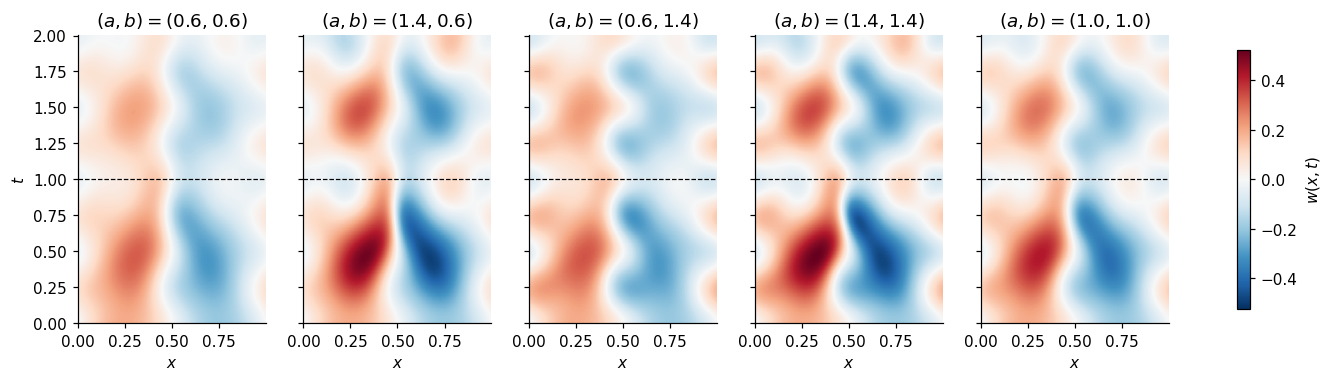

In [11]:
# Space-time maps of the five training trajectories (time upward).
vmax_ = max(np.abs(truth[p]).max() for p in TRAIN_PARAMS)
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4), sharey=True)
for ax, params in zip(axes, TRAIN_PARAMS):
    im = ax.pcolormesh(x, t_truth, truth[params].T, shading="auto",
                       cmap="RdBu_r", vmin=-vmax_, vmax=vmax_)
    ax.axhline(T_TRAIN[1], color="k", ls="--", lw=0.8)      # end of training window
    ax.set(title=f"$(a,b)=({params[0]},{params[1]})$", xlabel="$x$")
axes[0].set_ylabel("$t$")
fig.colorbar(im, ax=axes, label="$w(x,t)$", shrink=0.9)
plt.show()

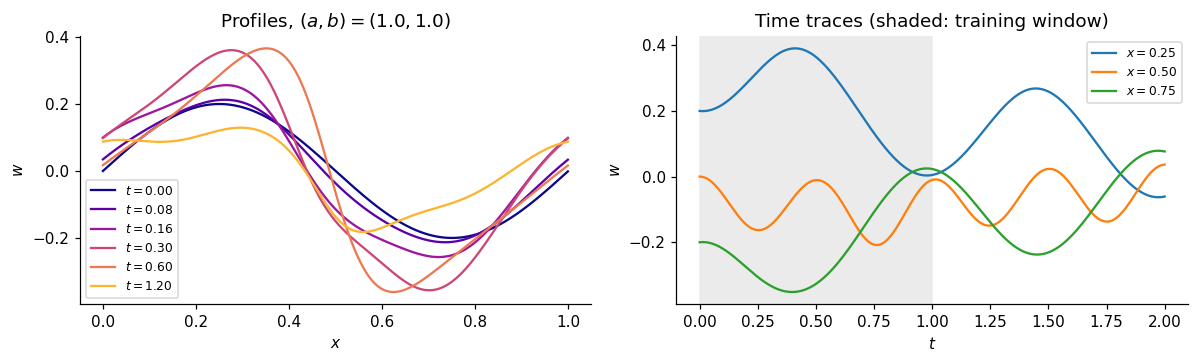

In [12]:
# Spatial profiles at a few times, and time traces at a few locations, for one trajectory.
params = TRAIN_PARAMS[4]
Q = truth[params]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

for j, tk in enumerate([0.0, 0.08, 0.16, 0.3, 0.6, 1.2]):
    idx = np.argmin(np.abs(t_truth - tk))
    axes[0].plot(x, Q[:, idx], color=plt.cm.plasma(j / 6), label=f"$t={t_truth[idx]:.2f}$")
axes[0].set(xlabel="$x$", ylabel="$w$", title=f"Profiles, $(a,b)={params}$")
axes[0].legend(fontsize=8)

for x_loc in [0.25, 0.5, 0.75]:
    i = np.argmin(np.abs(x - x_loc))
    axes[1].plot(t_truth, Q[i], label=f"$x={x[i]:.2f}$")
axes[1].axvspan(*T_TRAIN, color="0.92", zorder=-1)
axes[1].set(xlabel="$t$", ylabel="$w$", title="Time traces (shaded: training window)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. Sparse, noisy observations

### 4.1 Random observation times

For each trajectory independently:

$$
t_0 = 0,\qquad t_{m-1} = 1,\qquad t_1,\dots,t_{m-2}\ \overset{\text{iid}}{\sim}\ \mathcal U(0,1)\ \text{(sorted)},\qquad m = 30 .
$$

### 4.2 Relative noise

$$
\mathbf q_j = \mathbf q(t_j) + \boldsymbol\varepsilon_j,\qquad
\boldsymbol\varepsilon_j\sim\mathcal N\big(\mathbf 0,\ \mathrm{diag}(\xi\,\mathbf q(t_j))^2\big),
\qquad \xi = 0.03,
$$

entrywise $(\mathbf q_j)_i = w_i(t_j) + \xi|w_i(t_j)|z_{ij}$, with no noise at $t_0=0$ since the
initial condition is given.

In [13]:
def sample_times(m, t_span):
    # m sorted uniform times in t_span, with the first/last forced to the endpoints.
    t = np.sort(np.random.uniform(t_span[0], t_span[1], size=m))
    t[0], t[-1] = t_span
    return t

def add_noise(Q, xi):
    # Relative Gaussian noise on all nodes, at times t_j with j >= 1.
    # Q has shape (n, m); returns a noisy copy.
    Qn = Q.copy()
    body = Q[:, 1:]                                  # skip the first column (t_0)
    Qn[:, 1:] = body + xi * np.abs(body) * np.random.standard_normal(body.shape)
    return Qn

np.random.seed(SEED)

obs_times = []        # list of L arrays, shape (m,)
snapshots_clean = []  # list of L arrays, shape (n, m): exact solution at the observation times
snapshots = []        # list of L arrays, shape (n, m): noisy observations  <- the ONLY training data
for params in TRAIN_PARAMS:
    t_obs = sample_times(M, T_TRAIN)             # random draws 1: times
    Q_obs, _ = solve_fom(*params, t_obs)         # exact solution at those times
    Q_noisy = add_noise(Q_obs, XI)               # random draws 2: noise
    obs_times.append(t_obs)
    snapshots_clean.append(Q_obs)
    snapshots.append(Q_noisy)

print("snapshots per trajectory:", snapshots[0].shape,
      "  total:", sum(S.shape[1] for S in snapshots))

/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: divide by zero encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: overflow encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/244270976.py:5: RuntimeWarning: invalid value encountered in matmul
  return A @ q + quad_split(q) + B @ input_function(t, a, b)


snapshots per trajectory: (1024, 30)   total: 150


In [14]:
snapshots[0].shape, obs_times[0].shape

((1024, 30), (30,))

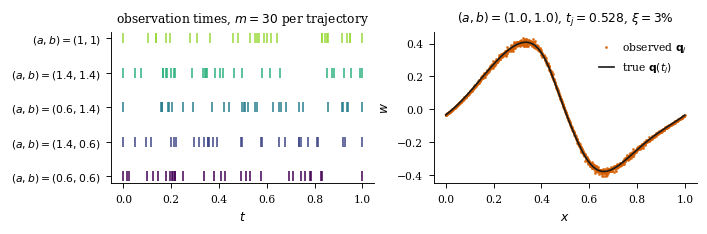

In [15]:
import matplotlib as mpl

PAPER_RC = {
    "font.family": "serif", "font.size": 8,
    "axes.labelsize": 8, "axes.titlesize": 8, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "lines.linewidth": 1.0, "pdf.fonttype": 42,
}
C_CON, C_UNC, C_SKEW = "#0072B2", "#D55E00", "#009E73"

with plt.rc_context(PAPER_RC):
    fig, axes = plt.subplots(1, 2, figsize=(6.3, 2.0))
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(TRAIN_PARAMS)))

    # Left: the irregular observation times of each trajectory.
    for l, (t_obs, params) in enumerate(zip(obs_times, TRAIN_PARAMS)):
        axes[0].plot(t_obs, np.full(M, l), "|", ms=6, color=colors[l])
    axes[0].set_yticks(range(len(TRAIN_PARAMS)))
    axes[0].set_yticklabels([f"$(a,b)=({a:g},{b:g})$" for a, b in TRAIN_PARAMS])
    axes[0].set(xlabel="$t$", title=f"observation times, $m={M}$ per trajectory")

    # Right: one noisy snapshot against the profile it was taken from.  The points
    # go down first and the clean profile on top: at xi = 3 % a line underneath the
    # markers is invisible.
    l, j = 4, 12
    axes[1].plot(x, snapshots[l][:, j], ".", ms=1.8, color=C_UNC, alpha=0.75,
                 label=r"observed $\mathbf{q}_j$", zorder=2)
    axes[1].plot(x, snapshots_clean[l][:, j], color="0.1", lw=1.1,
                 label=r"true $\mathbf{q}(t_j)$", zorder=3)
    axes[1].set(xlabel="$x$", ylabel="$w$",
                title=f"$(a,b)={TRAIN_PARAMS[l]}$, $t_j={obs_times[l][j]:.3f}$, "
                      f"$\\xi={XI:.0%}$".replace("%", r"\%"))
    axes[1].legend(frameon=False, handlelength=1.4)

    fig.tight_layout(pad=0.3)
    fig.savefig("fig_prob1_data.pdf", bbox_inches="tight")
    plt.show()

## 5. Compression

### 5.1 POD

The basis is centred on the snapshot mean $\bar{\mathbf q}$, the average of the snapshot
columns. Every exact snapshot has zero *spatial* mean, but their average over time does
not vanish, and centring on it is what puts the reduced coordinates around the origin. From
the thin SVD $\mathbf Q = \mathbf U\boldsymbol\Sigma\mathbf W^\top$ of all $L\times m = 150$
noisy snapshots *minus* $\bar{\mathbf q}$, the basis is $\mathbf V = \mathbf U_{:,1:r}$ with
$r=8$, and $\hat{\mathbf q}_j = \mathbf V^\top(\mathbf q_j-\bar{\mathbf q})$.

With the shift, the intrusive reduced operators are
$\widehat{\mathbf H}=\mathbf V^\top\mathbf H_F(\mathbf V\otimes\mathbf V)$, unchanged and still
energy preserving,
$\widehat{\mathbf A}=\mathbf V^\top(\mathbf A_F+2\mathbf H_F(\bar{\mathbf q}\otimes\mathbf I))\mathbf V$
and $\hat{\mathbf c}=\mathbf V^\top(\mathbf A_F\bar{\mathbf q}+\mathbf H_F(\bar{\mathbf q}\otimes\bar{\mathbf q}))$.

In [16]:
Q_all = np.hstack(snapshots)                        # (n, L*m) = (1024, 150), noisy
q_bar = Q_all.mean(axis=1)                          # the mean snapshot profile

U_svd, svals, _ = np.linalg.svd(Q_all - q_bar[:, None], full_matrices=False)
V = U_svd[:, :R]                                    # POD basis, (n, r)

def compress(Q):
    # Full snapshots (n, k) -> reduced coordinates (r, k)
    return V.T @ (Q - q_bar[:, None])

def decompress(Q_hat):
    # Reduced coordinates (r, k) -> full state (n, k)
    return V @ Q_hat + q_bar[:, None]

energy = np.cumsum(svals**2) / np.sum(svals**2)
print(f"snapshot matrix: {Q_all.shape}")
print(f"energy captured by r = {R} modes: {energy[R-1]:.8f}   "
      f"(residual {1 - energy[R-1]:.3e})")

# The intrusive linear operator about q_bar, and its decay rate.
# 2 H_F(q_bar x v) is recovered from quad_split by polarization.
Qbar = quad_split(q_bar)
Ahat = np.column_stack([V.T @ (A @ V[:, j]
                               + quad_split(q_bar + V[:, j]) - Qbar - quad_split(V[:, j]))
                        for j in range(R)])
chat = V.T @ (A @ q_bar + Qbar)
alpha = -np.linalg.eigvalsh(0.5 * (Ahat + Ahat.T)).max()
print(f"||q_bar|| = {np.linalg.norm(q_bar):.4f}")
print(f"alpha of the intrusive ROM = {alpha:.4f}   ||c_hat|| = {np.linalg.norm(chat):.4f}")

snapshot matrix: (1024, 150)
energy captured by r = 8 modes: 0.99635315   (residual 3.647e-03)
||q_bar|| = 5.7115
alpha of the intrusive ROM = 1.4460   ||c_hat|| = 9.4454


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:23: RuntimeWarning: divide by zero encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:23: RuntimeWarning: overflow encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:23: RuntimeWarning: invalid value encountered in matmul
  Ahat = np.column_stack([V.T @ (A @ V[:, j]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:26: RuntimeWarning: divide by zero encountered in matmul
  chat = V.T @ (A @ q_bar + Qbar)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:26: RuntimeWarning: overflow encountered in matmul
  chat = V.T @ (A @ q_bar + Qbar)
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:26: RuntimeWarning: invalid value encountered in ma

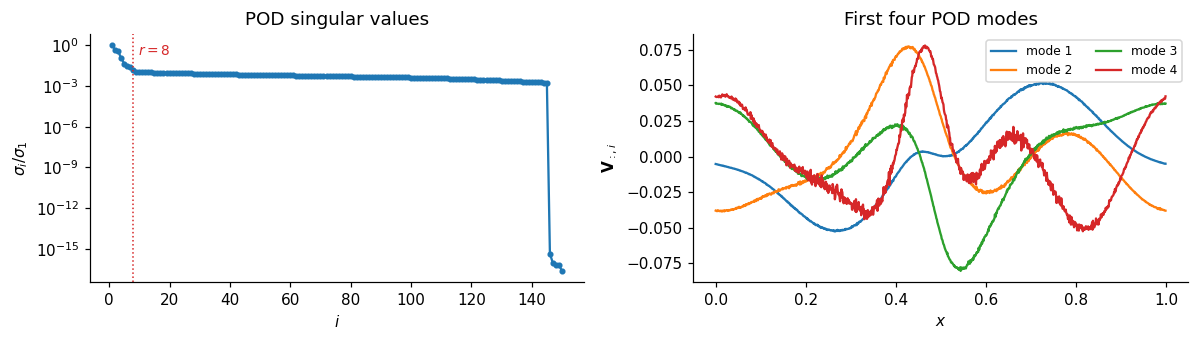

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].semilogy(np.arange(1, svals.size + 1), svals / svals[0], "o-", ms=3)
axes[0].axvline(R, color="C3", ls=":", lw=1)
axes[0].text(R + 1.5, 0.2, f"$r={R}$", color="C3", fontsize=9)
axes[0].set(xlabel="$i$", ylabel=r"$\sigma_i/\sigma_1$", title="POD singular values")

axes[1].plot(x, V[:, :4])
axes[1].set(xlabel="$x$", ylabel=r"$\mathbf{V}_{:,i}$", title="First four POD modes")
axes[1].legend([f"mode {i+1}" for i in range(4)], fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 5.2 The reduced coordinate time series

For every trajectory $\ell$ and reduced coordinate $i$ there is one short, irregular, noisy time
series $\{(t^{(\ell)}_j,\ \hat q^{(\ell)}_{i,j})\}_{j=0}^{m-1}$, $5\times8=40$ in total. The
lines show the noise-free reference solution compressed with the same basis. Only the first six
coordinates are plotted.

/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:9: RuntimeWarning: divide by zero encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:9: RuntimeWarning: overflow encountered in matmul
  return V.T @ (Q - q_bar[:, None])
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:9: RuntimeWarning: invalid value encountered in matmul
  return V.T @ (Q - q_bar[:, None])


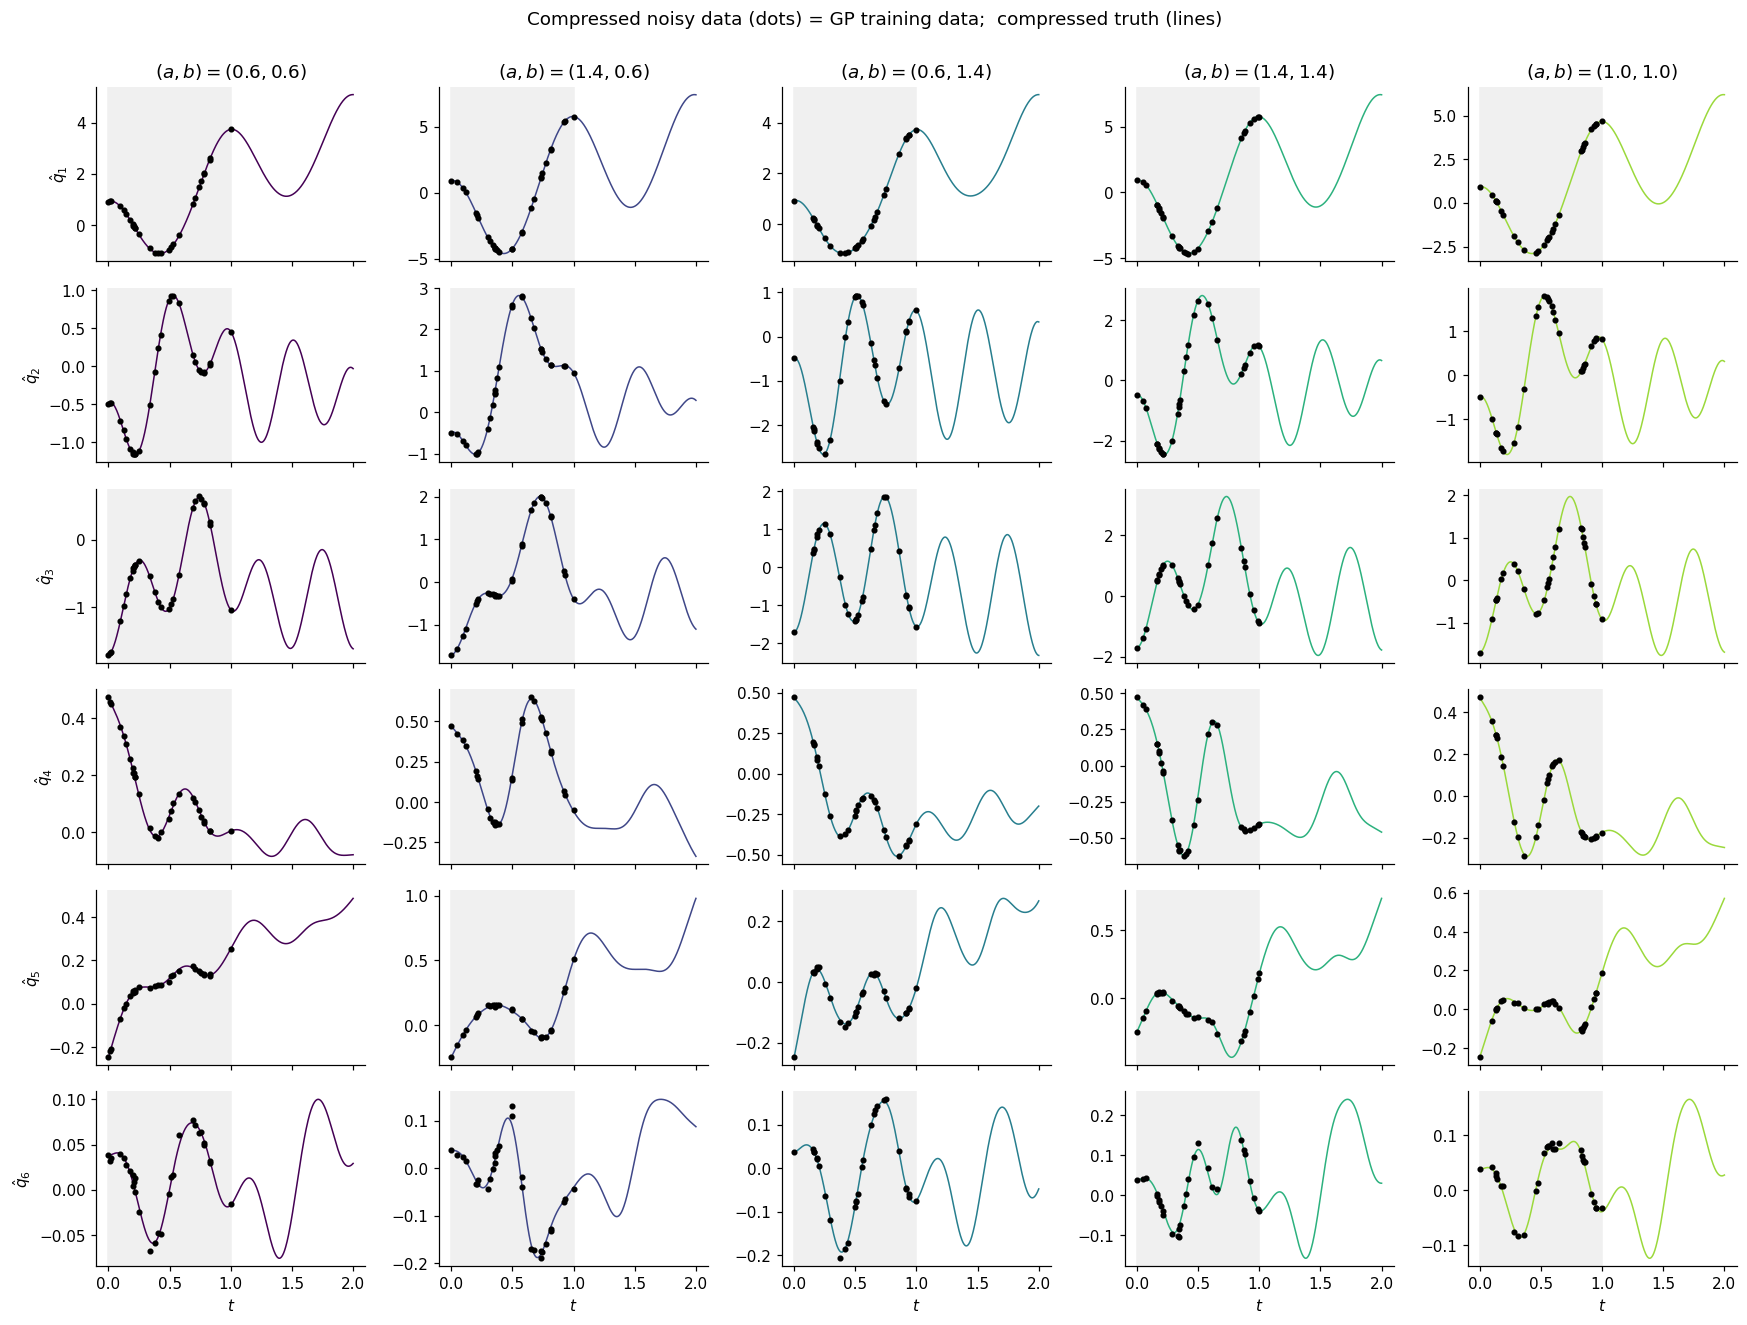

In [18]:
snapshots_compressed = [compress(S) for S in snapshots]           # list of (r, m)
truth_compressed = {p: compress(truth[p]) for p in truth}         # dict of (r, len(t_truth))

n_show = 6
fig, axes = plt.subplots(n_show, len(TRAIN_PARAMS), figsize=(16, 2.0 * n_show), sharex=True)
for l, params in enumerate(TRAIN_PARAMS):
    for i in range(n_show):
        ax = axes[i, l]
        ax.plot(t_truth, truth_compressed[params][i], color=colors[l], lw=1)
        ax.plot(obs_times[l], snapshots_compressed[l][i], "ko", ms=3)
        ax.axvspan(*T_TRAIN, color="0.94", zorder=-1)
        if i == 0:
            ax.set_title(f"$(a,b)=({params[0]},{params[1]})$")
        if l == 0:
            ax.set_ylabel(rf"$\hat q_{{{i+1}}}$")
for ax in axes[-1]:
    ax.set_xlabel("$t$")
fig.suptitle("Compressed noisy data (dots) = GP training data;  compressed truth (lines)", y=1.0)
plt.tight_layout()
plt.show()

### 5.3 Projection error

Even a perfect reduced model is limited by the basis. The projection error of the reference
solution,

$$
\frac{\|\mathbf Q_{\text{ref}} - \mathbf V\mathbf V^\top\mathbf Q_{\text{ref}}\|_F}
{\|\mathbf Q_{\text{ref}}\|_F},
$$

is a lower bound on the error of any reduced model in this basis. It is larger over $[0,2]$ than
over $[0,1]$ because the basis is built from snapshots in the training window only.

       (a,b)   proj. error [0,1]   proj. error [0,2]
  (0.6, 0.6)          7.8015e-03          1.7879e-02
  (1.4, 0.6)          9.9191e-03          2.0027e-02
  (0.6, 1.4)          1.1333e-02          1.7664e-02
  (1.4, 1.4)          9.8740e-03          1.8565e-02
  (1.0, 1.0)          6.5151e-03          1.6773e-02
(1.15, 0.85)          6.8695e-03          1.7543e-02  (test)


/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:13: RuntimeWarning: divide by zero encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:13: RuntimeWarning: overflow encountered in matmul
  return V @ Q_hat + q_bar[:, None]
/var/folders/23/tbg2wgfx04v2twjj_wj9c6wr0000gn/T/ipykernel_83679/3077447731.py:13: RuntimeWarning: invalid value encountered in matmul
  return V @ Q_hat + q_bar[:, None]


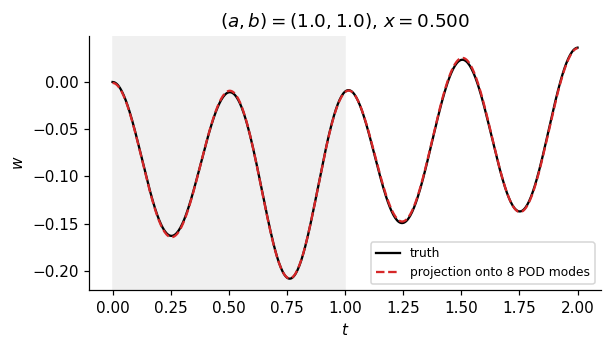

In [19]:
print(f"{'(a,b)':>12s}  {'proj. error [0,1]':>18s}  {'proj. error [0,2]':>18s}")
for params in TRAIN_PARAMS + [TEST_PARAMS]:
    Qt = truth[params]
    Qp = decompress(truth_compressed[params])
    train = t_truth <= T_TRAIN[1]
    e_tr = np.linalg.norm(Qt[:, train] - Qp[:, train]) / np.linalg.norm(Qt[:, train])
    e_all = np.linalg.norm(Qt - Qp) / np.linalg.norm(Qt)
    tag = "  (test)" if params == TEST_PARAMS else ""
    print(f"{str(params):>12s}  {e_tr:18.4e}  {e_all:18.4e}{tag}")

# Visual check at one location for one trajectory.
params, x_loc = TRAIN_PARAMS[4], 0.5
i = np.argmin(np.abs(x - x_loc))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t_truth, truth[params][i], "k", label="truth")
ax.plot(t_truth, decompress(truth_compressed[params])[i], "C3--",
        label=f"projection onto {R} POD modes")
ax.axvspan(*T_TRAIN, color="0.94", zorder=-1)
ax.set(xlabel="$t$", ylabel="$w$", title=f"$(a,b)={params}$, $x={x[i]:.3f}$")
ax.legend(fontsize=8)
plt.show()

## 6. Save the data

In [20]:
# The m' = 120 equally spaced times in [0, 1] at which the GP derivative estimates
# will be evaluated, and the inputs u(t) there for each training trajectory.
t_est = np.linspace(*T_TRAIN, M_PRIME)
inputs_est = np.array([input_function(t_est, *p) for p in TRAIN_PARAMS])   # (L, 2, m')

np.savez_compressed(
    "data_Burgers1D.npz",
    # configuration
    nu=NU, xi=XI, r=R, seed=SEED, dx=dx,
    train_params=np.array(TRAIN_PARAMS), test_params=np.array(TEST_PARAMS),
    x=x, t_truth=t_truth, t_est=t_est,
    # training data (what the method is allowed to see)
    obs_times=np.array(obs_times),                       # (L, m)
    snapshots=np.array(snapshots),                       # (L, n, m)   noisy
    snapshots_clean=np.array(snapshots_clean),           # (L, n, m)   noise free
    snapshots_compressed=np.array(snapshots_compressed), # (L, r, m)
    inputs_est=inputs_est,                               # (L, 2, m')
    # POD basis
    V=V, q_bar=q_bar, svals=svals,
    # the input matrix; A_F is not stored because it is fully determined by
    # (nu, dx): A_F = (nu/dx^2) * circ(1, -2, 1), three lines to rebuild.
    B_F=B,
    # truth (for evaluation only)
    truth_train=np.array([truth[p] for p in TRAIN_PARAMS]),   # (L, n, 501)
    truth_test=truth[TEST_PARAMS],                            # (n, 501)
)
print("saved data_Burgers1D.npz")

saved data_Burgers1D.npz
